In [ ]:
using Lattices
using LinearAlgebra
using Combinatorics
using SparseArrays
using CairoMakie
import Graphs
using LaTeXStrings
using Statistics
using Random
using Zygote
using Optimization, OptimizationOptimisers
using JSON
using OptimizationOptimJL
using JLD2
using ExponentialUtilities
using LsqFit
# using CUDA
using HDF5

using DataFrames, CSV

if !isdefined(Main, :UtilityFunctions)
    include("utility_functions.jl")
end
include("ed_objects.jl")
include("ed_functions.jl")
include("ed_optimization.jl")
include("data_path.jl")
# create_fig, get_figsize, cmap1/cmap2, LEGEND_ARGS, the theme, label_panels! and
# annotate_panel! all come from fig_lib.jl -- don't redefine them here
include("fig_lib.jl")


const FILE_LABEL_PAIRS = [
    (L"3\times 2\;(2,2)",   "N=(2, 2)_3x2", (2,2)),
    (L"3\times 2,\;(3,2)",  "N=(3, 2)_3x2", (3,2)),
    (L"3\times 2,\;(3,3)",  "N=(3, 3)_3x2", (3,3)),
    (L"3\times3,\;(3,2)",   "N=(3, 2)_3x3", (3,2)),
    (L"4\times2,\;(3,3)",   "N=(3, 3)_4x2", (3,3)),
    (L"3\times3,\;(3,3)",   "N=(3, 3)_3x3", (3,3)),
    (L"3\times3,\;(4,3)",   "N=(4, 3)_3x3", (4,3)),
    (L"3\times3,\;(4,4)",   "N=(4, 4)_3x3", (4,4)),
    (L"3\times3,\;(5,4)",   "N=(5, 4)_3x3", (5,4)),
    # (L"4\times3,\;(4,4)",   "N=(4, 4)_4x3", (4,4)),
    (L"4\times3,\;(5,4)",   "N=(5, 4)_4x3", (5,4)),
]

const FOLDER = get_data_root()

"/home/jek354/research/data/new_data/data_h5_fixed"

In [7]:
using CSV
using DataFrames
file = "/home/jek354/research/ML-signproblem/experimenting/ed/data-summary/fig2.csv"
df = CSV.read(file, DataFrame)
df[!,:loss_ratio] = (1 .-df[!,:baseline_overlap])./(1 .-df[!,:optimized_overlap])
df[df.system_size .== "\$3\\times 2\\;(2,2)\$",:]

Row,system_size,hilbert_space_size,U,optimized_overlap,baseline_overlap,overlap_ratio,loss_ratio
,String31,Int64,Float64,Float64,Float64,Float64,Float64
1,"$3\\times 2\\;(2,2)$",39,0.5,1.0,0.499909,2.00036,8.34375e8
2,"$3\\times 2\\;(2,2)$",39,0.75,1.0,0.499636,2.00146,7.80903e9
3,"$3\\times 2\\;(2,2)$",39,1.0,1.0,0.499184,2.00327,1.54466e10
4,"$3\\times 2\\;(2,2)$",39,1.25,1.0,0.498554,2.0058,1.38649e11
5,"$3\\times 2\\;(2,2)$",39,1.5,1.0,0.49775,2.00904,8.24921e11
6,"$3\\times 2\\;(2,2)$",39,1.75,1.0,0.496777,2.01297,1.10498e12
7,"$3\\times 2\\;(2,2)$",39,2.0,1.0,0.495641,2.01759,5.1741e12
8,"$3\\times 2\\;(2,2)$",39,2.25,1.0,0.494348,2.02287,8.52905e12
9,"$3\\times 2\\;(2,2)$",39,2.5,1.0,0.492904,2.02879,2.77829e12


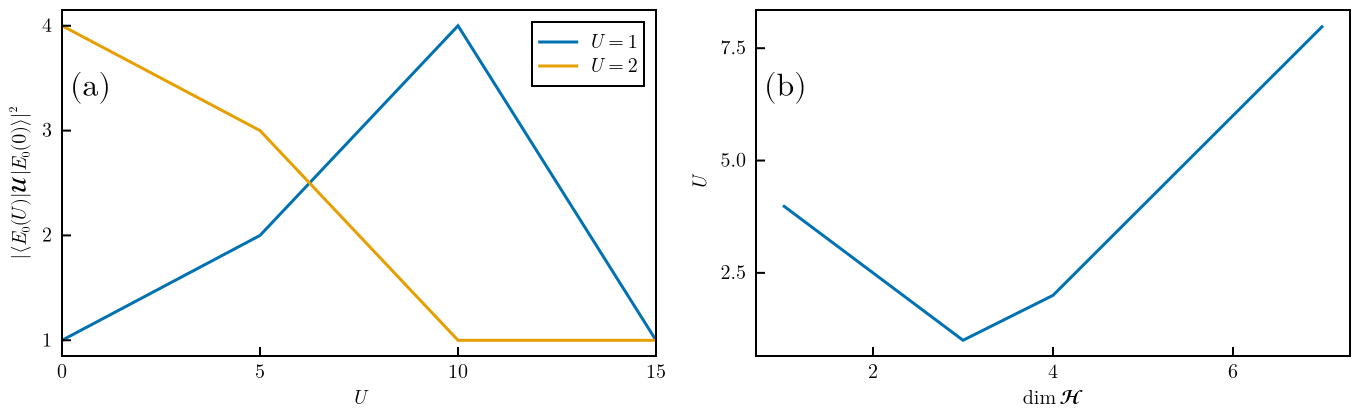

CairoMakie.Screen{IMAGE}


In [2]:
fig, ax = create_fig(2, 55.0;
    xlabel = L"U",
    ylabel = L"|\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2",
    limits = ((0, 15),(nothing, nothing)),
)
lines!(ax, [0,5,10,15],[1,2,4,1], label=L"U=1")
lines!(ax, [0,5,10,15],[4,3,1,1], label=L"U=2")
# Legend(fig[1,2], ax)
axislegend(ax; LEGEND_ARGS...)

ax2 = Axis(fig[1, 2]; xlabel=L"\dim \mathcal{H}", ylabel=L"U", AXIS_ARGS...)
lines!(ax2, [1,3,4,7],[4,1,2,8])
# label_panels!(fig; format=l->"$l", font=:bold, padx=20, fontsize=16)
label_panels!(fig; placement=:inside, corner=:lt,padx=10, fontsize=16)
save("deleteme.pdf", fig)
display(fig)


In [38]:
for (_, folder,_) in FILE_LABEL_PAIRS
    U_values, target_vecs, indexer, precomputed_structures, N, spin_conserved, use_symmetry, sign_convention = load_ED_data(data_folder(folder); sign_convention=:spin_first, use_slater_reference=false)
    println(folder, " ", size(target_vecs,2))
end

N=(2, 2)_3x2 39
N=(3, 2)_3x2 50
N=(3, 3)_3x2 68
N=(3, 2)_3x3 336
N=(3, 3)_4x2 392
N=(3, 3)_3x3 792
N=(4, 3)_3x3 1176
N=(4, 4)_3x3 1764
N=(5, 4)_3x3 1764
N=(4, 4)_4x3 20439
N=(5, 4)_4x3 32670


In [10]:
dict = load("/home/jek354/research/data/new_data/data_h5_fixed/N=(3, 3)_3x3/trotter_N=9_num_exponentials=2_ref_slater_antihermitian_u_23.jld2")["dict"]["metrics"]

Dict{String, Vector{Any}} with 9 entries:
  "multistart_losses"   => [Vector{Float64}[]]
  "other"               => []
  "best_start_idx"      => [0]
  "stopping_reasons"    => [["Maximum iterations reached (maxiters)", "Maximum …
  "optimization_losses" => [[0.000321566, 0.000307711, 0.000300555, 0.000292237…
  "convergence_info"    => [Dict{String, Any}[Dict("optimizer"=>"LBFGS", "itera…
  "energy"              => [-6.5, -9.38573, -9.85437]
  "loss_std"            => [0.0]
  "loss"                => [0.850795, 2.73167e-6]

## Loss curves
In this figure, for the $(N_\uparrow, N_\downarrow)=(4,4)$ on the $3\times 3$ system, I plotted the loss curves of the optimization dependent on the $U$ value. This plot confirms that there is no reason to not reuse the reference state for the prior $U$ value. It's not stuck in a local minimum, it simply can't find a better state. The solid lines correspond to using the previous $U$ value's coefficients as initial coefficients, and the dotted line corresponds to randomly generating the coefficients each time.

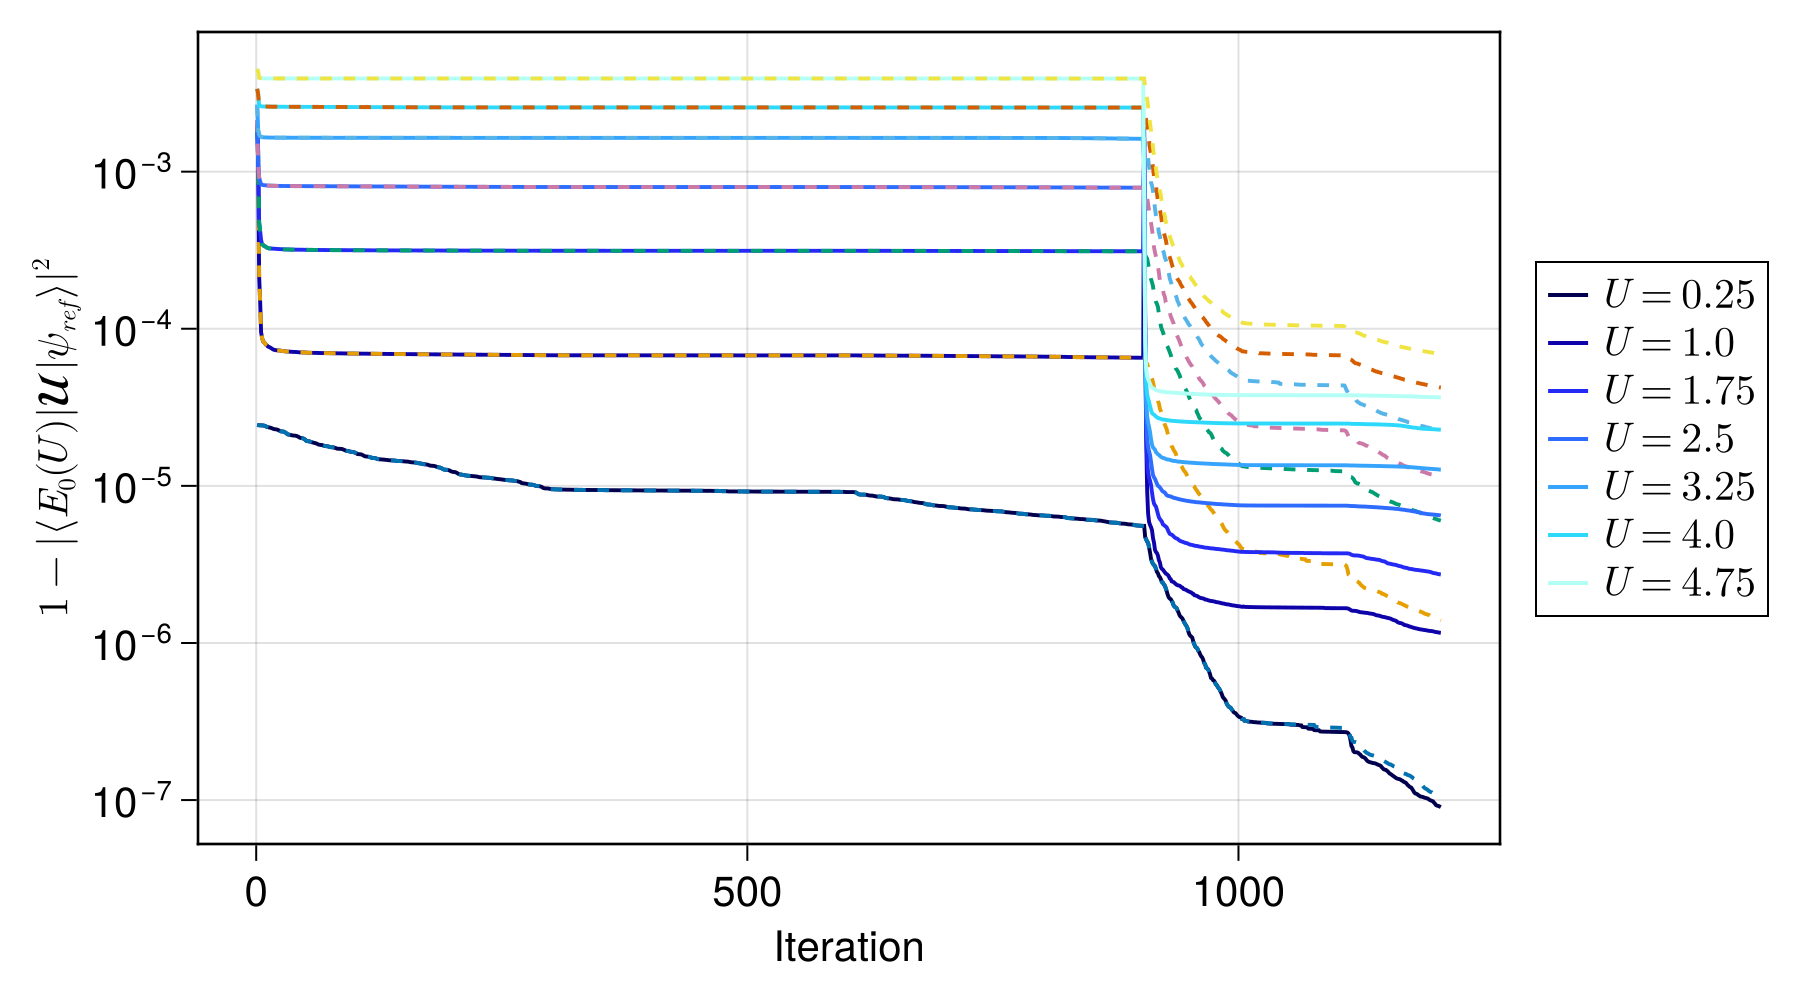

CairoMakie.Screen{IMAGE}


In [ ]:
# loss curves when adding an extra num_exponential

electrons = (4, 4)
site_dim = (3, 3)
u_indices = 2:3:20

fig = Figure(size=(900, 500))
ax = Axis(fig[1, 1];
    xlabel="Iteration",
    ylabel=L"1 - |\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2",
    yscale=log10,
)

colors = cmap1(length(u_indices))


for (c_i, u_idx) in enumerate(u_indices)
    filename_prefix = build_save_name_prefix(:trotter;
        sites=prod(site_dim),
        antihermitian=true, 
        custom_ref_state_arg="slater",
         num_exponentials=1,
        )
    filepath = data_folder("N=$(electrons)_$(join(site_dim, "x"))/$(filename_prefix)_u_$u_idx.jld2")
    dict = load_saved_dict(filepath)

    filename_prefix = build_save_name_prefix(:trotter;
        sites=prod(site_dim),
        antihermitian=true, 
        custom_ref_state_arg="slater",
         num_exponentials=2,
        )
    filepath = data_folder("N=$(electrons)_$(join(site_dim, "x"))/$(filename_prefix)_u_$u_idx.jld2")
    dict2 = load_saved_dict(filepath)

        filename_prefix = build_save_name_prefix(:trotter;
        sites=prod(site_dim),
        antihermitian=true, 
        custom_ref_state_arg="slater",
         num_exponentials=2,
         suffix="u_build"
        )
    filepath = data_folder("N=$(electrons)_$(join(site_dim, "x"))/$(filename_prefix)_u_$u_idx.jld2")
    dict3 = load_saved_dict(filepath)
    l = lines!(ax, [dict["metrics"]["optimization_losses"][1];dict2["metrics"]["optimization_losses"][1]];
        color=colors[c_i],
        label=L"U=%$((u_idx-1)*0.25)")
    l = lines!(ax, [dict["metrics"]["optimization_losses"][1];dict3["metrics"]["optimization_losses"][1]];
        label=L"U=%$((u_idx-1)*0.25)", linestyle=:dash)
end


# Build per-U legend entries
u_entries = [LineElement(color=colors[i], linewidth=2) for i in eachindex(u_indices)]
u_labels  = [L"U=%$((u_idx-1)*0.25)" for u_idx in u_indices]

Legend(fig[1, 2],
    [u_entries...],
    [u_labels...])


display(fig)

# Continuity of coefficients

In [34]:
filename_prefix = build_save_name_prefix(:trotter;
    sites=prod(site_dim),
    antihermitian=true, 
    custom_ref_state_arg="slater",
    num_exponentials=2,
    suffix="u_build"
)

coefs = []
for u_idx in 2:15
    filepath = data_folder("N=$(electrons)_$(join(site_dim, "x"))/$(filename_prefix)_u_$u_idx.jld2")
    dict = load_saved_dict(filepath)
    push!(coefs, dict["coefficients"])
end
println(length(coefs[1]))
[maximum(abs.(coefs[i+1] - coefs[i])) for i=1:10]


864


10-element Vector{Float64}:
 0.26149982900970936
 0.14504897816108414
 0.2548050949520976
 0.26008633922270524
 0.3212918872768566
 0.2624869174032506
 0.49228644935092597
 0.518928261876199
 0.7579919505238837
 0.4212499445439922

# Figure 2

Using width=7.086614173228347" and height=2.7559055118110236"


[0.4999089971486379, 0.49963644355803005, 0.4991838606045542, 0.4985538653237518, 0.4977501266477721, 0.496777304789362, 0.4956409757158593, 0.49434754306802897, 0.4929041401713754, 0.49131852495339856, 0.48959897061948043, 0.4877541548609772, 0.4857930501865322, 0.48372481770123743, 0.4815587063303891, 0.47930395911837054, 0.4769697278508014, 0.474564996869393, 0.47209851659048063, 0.46957874691269585, 0.46701381041553547, 0.46441145501367154, 0.46177902554348405, 0.45912344361745294, 0.45645119498554343, 0.45376832358601193, 0.451080431445557, 0.4483926835946547, 0.44570981719227265, 0.44303615409952557, 0.44037561619905796, 0.4377317428217713, 0.4351077097111685, 0.4325063490251536, 0.42993016994324373, 0.4273813795121164, 0.4248619034230201, 0.4223734064700355, 0.41991731248812414, 0.4174948236141496, 0.4151069387527586, 0.41275447116234143, 0.4104380651046574, 0.40815821152547893, 0.40591526275325496, 0.4037094462187566, 0.40154087721141873, 0.39940957069802563, 0.3973154522369384

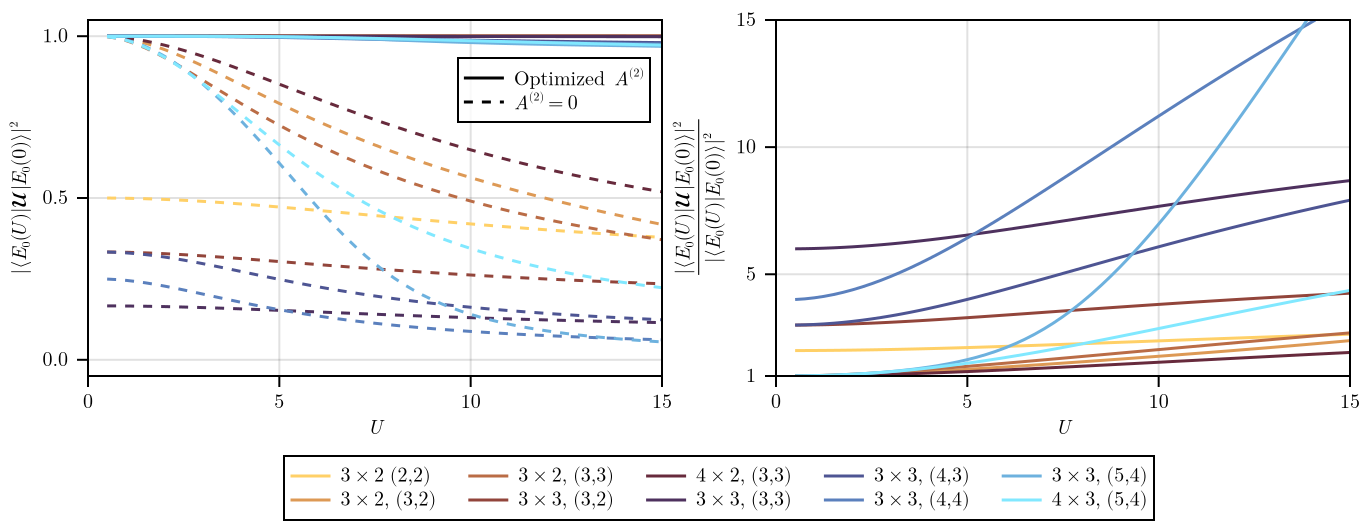

CairoMakie.Screen{PDF}


In [7]:
fig_overlap, ax_overlap = create_fig(2, 70.0;
    xlabel = L"U",
    ylabel = L"|\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2",
    limits = ((0, 15), (-0.05, 1.05)),
)

# fig_improvement = Figure()
ax_improvement = Axis(fig_overlap[1, 2];
    aspect = (1+sqrt(5))/2,
    xlabel = L"U",
    ylabel = L"\frac{|\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2}{|\langle \Psi_{\mathbf{K}}(U)|\Phi_{\mathbf{K}}\rangle|^2}",
    limits = ((0, 15), (1, 15)),
    yticks = [1,5,10,15]
)

hilbert_space_sizes = []
final_performances = []
num_tuning_parameters = []

u_indices = 2:60
palette_colors = cmap2(length(FILE_LABEL_PAIRS))


selected_u_indices = [20, 30, 45]
palette_colors2 = cmap2(length(selected_u_indices))

for (sys_idx, (display_label, file_label, electron_counts)) in enumerate(FILE_LABEL_PAIRS)
    sys_dir = joinpath(FOLDER, file_label)
    if !isdir(sys_dir)
        @warn "Directory for system $file_label does not exist: $sys_dir. Skipping."
        continue
    end

    num_sites = prod(parse_lattice_dimension(file_label))
    prefix = build_save_name_prefix(:trotter;
        electrons = electron_counts, sites = num_sites,
        antihermitian = true, custom_ref_state_arg = "slater")

    meta_file = joinpath(sys_dir, "meta_data_and_E.jld2")
    if isfile(meta_file)
        metadata_dict = load(meta_file)["dict"]
        hilbert_space_size = size(metadata_dict["all_full_eig_vecs"][1], 2)
        interaction_data = metadata_dict["meta_data"]["U_values"]
    else
        valid_files = [f for f in readdir(sys_dir) if occursin("HubbardED", f)]
        if isempty(valid_files)
            @warn "No meta_data_and_E.jld2 or HubbardED HDF5 files found in $sys_dir. Skipping."
            continue
        end
        interaction_data = nothing
        hilbert_space_size = nothing
        h5open(joinpath(sys_dir, valid_files[1]), "r") do h5data
            global interaction_data = read(h5data["data/uvec"])
            global hilbert_space_size = length(read(h5data["data/evecs/0"])[:, 1, 1])
        end
    end

    coefficients_list = []
    optimized_overlaps = Float64[]
    second_order_overlaps = Float64[]
    baseline_overlaps = Float64[]

    valid_u_indices = Int[]
    for u_idx in u_indices
        filepath = joinpath(sys_dir, "$(prefix)_u_$(u_idx).jld2")
        if !isfile(filepath)
            continue
        end
        result_dict = load_saved_dict(filepath)

        push!(valid_u_indices, u_idx)
        push!(coefficients_list, result_dict["coefficients"][2])
        push!(optimized_overlaps, 1 - result_dict["metrics"]["loss"][2])
        if length(result_dict["metrics"]["loss"]) > 2
            push!(second_order_overlaps, 1 - result_dict["metrics"]["loss"][3])
        end
        push!(baseline_overlaps, 1 - result_dict["metrics"]["loss"][1])
    end
    println(baseline_overlaps)

    if isempty(valid_u_indices)
        @warn "No valid optimization files found for $file_label. Skipping."
        continue
    end

    coef_matrix = reduce(hcat, coefficients_list)

    # Coefficient trajectory plot
    fig_trajectory = Figure()
    ax_trajectory = Axis(fig_trajectory[1, 1];
        xlabel = L"U",
        ylabel = L"A^{(2)} \;\textrm{value}",
        limits = ((0, 10), (-0.5, 0.5)),
    )
    for col in eachcol(coef_matrix)
        lines!(ax_trajectory, interaction_data[valid_u_indices], col; color = (:royalblue1, 0.06))
    end
    for (color_idx, u_idx) in enumerate(selected_u_indices)
        if u_idx in valid_u_indices
            vlines!(ax_trajectory, [interaction_data[u_idx]];
                color = palette_colors2[color_idx], linestyle = :dash,
                label = L"U=%$(round(interaction_data[u_idx], digits=2))")
        end
    end
    axislegend(ax_trajectory; position = :rt, backgroundcolor = (:white, 0.8))

    # Main overlap curves
    lines!(ax_overlap, interaction_data[valid_u_indices], baseline_overlaps;
        color = palette_colors[sys_idx], linestyle = :dash)
    lines!(ax_overlap, interaction_data[valid_u_indices], optimized_overlaps;
        color = palette_colors[sys_idx]#, label = string(display_label)
        )

    # Improvement ratios
    overlap_improvement_ratios = optimized_overlaps ./ baseline_overlaps
    target_u_val = 10
    lines!(ax_improvement, interaction_data[valid_u_indices], overlap_improvement_ratios;
        color = palette_colors[sys_idx], label = string(display_label))

    target_idx = argmin(abs.(interaction_data .- target_u_val)) + valid_u_indices[1] - 1
    push!(final_performances, overlap_improvement_ratios[min(target_idx, length(overlap_improvement_ratios))])
    push!(hilbert_space_sizes, hilbert_space_size)

    dimension_match = match(r"(?<N>\d+)[xX](?<M>\d+)", file_label)
    push!(num_tuning_parameters, get_num_2nd_order_coef(
        parse(Int, dimension_match[:N]),
        parse(Int, dimension_match[:M])
    ))

    # Histogram at selected U values
    # for (color_idx, u_idx) in enumerate(selected_u_indices)
    #     filepath = joinpath(sys_dir, "$(prefix)_u_$(u_idx).jld2")
    #     if !isfile(filepath)
    #         continue
    #     end
    #     result_dict = load_saved_dict(filepath)
    #     coef_values = result_dict["coefficients"]
    #     if length(coef_values) < 5
    #         coef_values = coef_values[2]
    #     end

        # fig_histogram = Figure()
        # ax_histogram = Axis(fig_histogram[1, 1];
        #     xlabel = L"A^{(2)}\;\textrm{value}",
        #     ylabel = L"\textrm{Count}",
        #     limits = ((-0.5, 0.5), (0, nothing)),
        #     xticks = -0.5:0.25:0.5,
        # )
        # hist!(ax_histogram, coef_values;
        #     bins = LinRange(-0.5, 0.5, 50),
        #     color = palette_colors[color_idx],
        #     label = L"U=%$(round(interaction_data[u_idx], digits=2))", strokewidth=2)
        # axislegend(ax_histogram; position = :rt, backgroundcolor = (:white, 0.8))
        # display(fig_histogram)

        # mkpath("good_images/antihermitian")
        # save("good_images/antihermitian/U=$(round(interaction_data[u_idx], digits=2))_$(file_label)_histogram.png", fig_histogram)
        # save("good_images/antihermitian/U=$(round(interaction_data[u_idx], digits=2))_$(file_label)_histogram.pdf", fig_histogram)
    # end
end

# Style legend entries for main overlap figure
lines!(ax_overlap, [NaN], [NaN];
    color = :black, linestyle = :solid,
    label = L"\textrm{Optimized}\;\,A^{(2)} ")
lines!(ax_overlap, [NaN], [NaN];
    color = :black,linestyle = :dash,
    label = L"A^{(2)}=0")

Legend(fig_overlap[2,1:2], ax_improvement, orientation=:horizontal, nbanks=2; LEGEND_ARGS...)
# Legend(fig_improvement[1,3], ax_improvement)
axislegend(ax_overlap; backgroundcolor = (:white, 0.8), position=(1,0.9),LEGEND_ARGS...)
# axislegend(ax_improvement; position = :lt, backgroundcolor = (:white, 0.8))
rowgap!(fig_overlap.layout, 5)
colgap!(fig_overlap.layout, 5)
label_panels!(fig_overlap)
display(fig_overlap)
# display(fig_improvement)

save("good_images/final/loss_curve.png", fig_overlap)
save("good_images/final/loss_curve.pdf", fig_overlap)
# save("good_images/final/extra/loss_improvement2.png", fig_sub)
# save("good_images/final/extran/loss_improvement2.pdf", fig_sub)


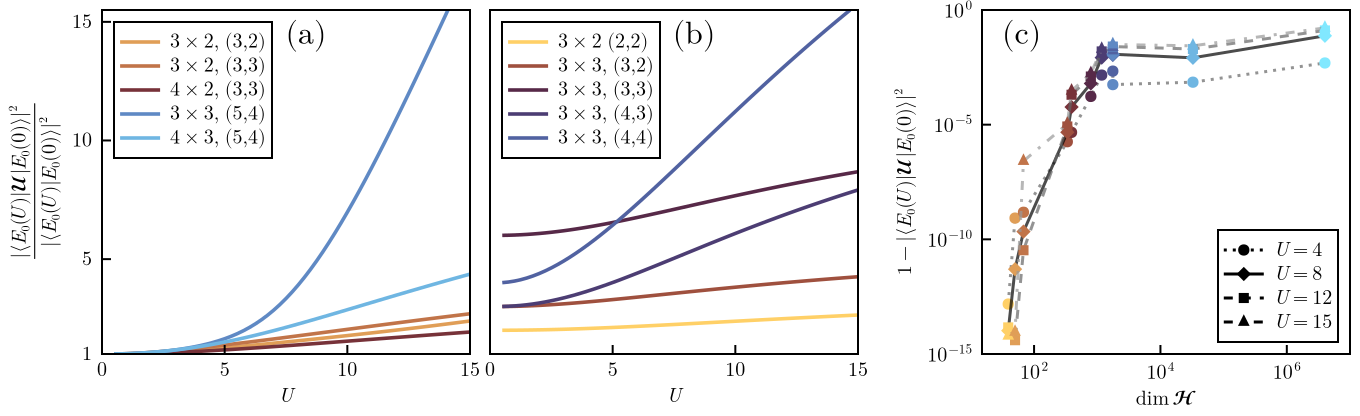

"data-summary/fig2.csv"

In [25]:
# ==============================================================================
# 5-Panel Figure: Overlap Improvement Ratio (a, b) and the bare overlap it is a ratio of (d, e),
# split by Small-U Baseline; DimH Infidelity (c)
# ==============================================================================

df_fig2 = DataFrame(system_size=String[], hilbert_space_size=Int[], U=Float64[], optimized_overlap=Float64[], baseline_overlap=Float64[], overlap_ratio=Float64[])

# Panel 1: Systems starting near baseline for small U
fig2, ax1 = create_fig(2, 62.0;
    xlabel = L"U",
    ylabel = L"\mathcal{F}/\mathcal{F}_0",
    limits = ((0, 15), (1, 15.5)),
    yticks = [1, 5, 10, 15],
    aspect = :auto,
)

# Panel 2: Systems starting noticeably greater than baseline for small U
ax2 = Axis(fig2[1, 2];
    xlabel = L"U",
    limits = ((0, 15), (1, 15.5)),
    yticks = [1, 5, 10, 15],
    AXIS_ARGS...,
)
hideydecorations!(ax2, grid = false)

# Panel 3: Infidelity vs dimH across multiple U values
ax3 = Axis(fig2[1:2, 3];
    xlabel = L"\dim \mathcal{H}",
    ylabel = L"1 - \mathcal{F}",
    xscale = log10,
    yscale = log10,
    limits = ((15, 1e7), (1e-15, 1.0)),
    AXIS_ARGS...,
)

# Axis symbols (defined in the paper, ¶12): F = |<Psi_K(U)|U_A|Phi_K>|^2 is the fidelity of the optimized
# layer, F_0 = |<Psi_K(U)|Phi_K>|^2 that of the reference alone (the baseline, F at A = 0).
# Panels 4 and 5 (d, e): the baseline fidelity F_0, under the ratio panels and sharing their U axis and systems, so the legends of (a)
# and (b) serve them too. The small headroom above 1 (y limit 1.08) and the row gap of 7 keep the
# "1.0" tick label clear of the "1" at the bottom of the ratio panel above.
ax1b = Axis(fig2[2, 1]; xlabel = L"U", ylabel = L"\mathcal{F}_0",
    limits = ((0, 15), (0, 1.08)), yticks = [0, 0.5, 1], AXIS_ARGS...)
ax2b = Axis(fig2[2, 2]; xlabel = L"U",
    limits = ((0, 15), (0, 1.08)), yticks = [0, 0.5, 1], AXIS_ARGS...)
hideydecorations!(ax2b, grid = false)
linkxaxes!(ax1, ax1b); linkxaxes!(ax2, ax2b)
hidexdecorations!(ax1, grid = false); hidexdecorations!(ax2, grid = false)
rowsize!(fig2.layout, 2, Relative(0.32))
rowgap!(fig2.layout, 1, 7)

u_indices = 2:60
palette_colors = cmap2(length(FILE_LABEL_PAIRS) + 1)
selected_U_values = [4.0, 8.0, 12.0, 15.0]
num_u = length(selected_U_values)

dimH_list = Float64[]
losses_by_u = [Float64[] for _ in 1:num_u]

# Styling for multiple U values in Panel 3
u_linestyles = [:dot, :solid, :dash, :dashdot]
u_markers = [:circle, :diamond, :rect, :utriangle]
u_line_colors = [(:gray40, 0.7), (:black, 0.7), (:gray40, 0.7), (:gray60, 0.7)]

for (sys_idx, (display_label, file_label, electron_counts)) in enumerate(FILE_LABEL_PAIRS)
    sys_dir = joinpath(FOLDER, file_label)
    if !isdir(sys_dir)
        @warn "Directory for system $file_label does not exist: $sys_dir. Skipping."
        continue
    end

    num_sites = prod(parse_lattice_dimension(file_label))
    prefix = build_save_name_prefix(:trotter;
        electrons = electron_counts, sites = num_sites,
        antihermitian = true, custom_ref_state_arg = "slater")

    meta_file = joinpath(sys_dir, "meta_data_and_E.jld2")
    local hilbert_space_size, interaction_data
    if isfile(meta_file)
        metadata_dict = load(meta_file)["dict"]
        hilbert_space_size = size(metadata_dict["all_full_eig_vecs"][1], 2)
        interaction_data = metadata_dict["meta_data"]["U_values"]
    else
        valid_files = [f for f in readdir(sys_dir) if occursin("HubbardED", f)]
        if isempty(valid_files)
            @warn "No meta_data_and_E.jld2 or HubbardED HDF5 files found in $sys_dir. Skipping."
            continue
        end
        h5open(joinpath(sys_dir, valid_files[1]), "r") do h5data
            interaction_data = read(h5data["data/uvec"])
            hilbert_space_size = size(h5data["data/evecs/0"], 1)
        end
    end

    optimized_overlaps = Float64[]
    baseline_overlaps = Float64[]
    optimized_losses = Float64[]
    valid_u_indices = Int[]

    for u_idx in u_indices
        filepath = joinpath(sys_dir, "$(prefix)_u_$(u_idx).jld2")
        if !isfile(filepath)
            continue
        end
        result_dict = load_saved_dict(filepath)

        push!(valid_u_indices, u_idx)
        push!(optimized_losses, result_dict["metrics"]["loss"][2])
        push!(optimized_overlaps, 1.0 - result_dict["metrics"]["loss"][2])
        push!(baseline_overlaps, 1.0 - result_dict["metrics"]["loss"][1])

        push!(df_fig2, [display_label,hilbert_space_size, interaction_data[u_idx], optimized_overlaps[end],  baseline_overlaps[end], optimized_overlaps[end]/baseline_overlaps[end]])
    end

    if isempty(valid_u_indices)
        @warn "No valid optimization files found for $file_label. Skipping."
        continue
    end

    overlap_improvement_ratios = optimized_overlaps ./ baseline_overlaps


    # Partition: initial ratio noticeably > 1 (e.g. > 1.5) goes to Panel 2, otherwise Panel 1
    initial_ratio = overlap_improvement_ratios[1]
    target_ax = initial_ratio > 1.5 ? ax2 : ax1

    lines!(target_ax, interaction_data[valid_u_indices], overlap_improvement_ratios;
        color = palette_colors[sys_idx], label = string(display_label), linewidth = 1.8)
    lines!(target_ax === ax1 ? ax1b : ax2b, interaction_data[valid_u_indices], baseline_overlaps;
        color = palette_colors[sys_idx], linewidth = 1.8)

    # Collect data for Panel 3 across all selected U values
    push!(dimH_list, Float64(hilbert_space_size))
    for (k, u_target) in enumerate(selected_U_values)
        target_idx = argmin(abs.(interaction_data[valid_u_indices] .- u_target))
        push!(losses_by_u[k], optimized_losses[target_idx])
    end
end

# Append 4x4 data to Panel 3 and df_fig2
sys_dir_4x4 = joinpath(FOLDER, "N=(6, 6)_4x4")
if isdir(sys_dir_4x4)
    display_label_4x4 = L"4\times 4,\;(6,6)"
    hilbert_space_size_4x4 = 4008592
    push!(dimH_list, Float64(hilbert_space_size_4x4))

    u_files_4x4 = Dict(
        4.0 => "trotter_N=16_ref_slater_antihermitian_u_17.jld2",
        8.0 => "trotter_N=16_ref_slater_antihermitian_u_33.jld2",
        12.0 => "trotter_N=16_ref_slater_antihermitian_u_49.jld2",
        15.0 => "trotter_N=16_ref_slater_antihermitian_u_61.jld2",
    )

    for (k, u_target) in enumerate(selected_U_values)
        if haskey(u_files_4x4, u_target)
            fpath = joinpath(sys_dir_4x4, u_files_4x4[u_target])
            if isfile(fpath)
                m = load(fpath)["dict"]["metrics"]
                loss_opt = Float64(m["loss"][2])
                loss_base = Float64(m["loss"][1])
                push!(losses_by_u[k], loss_opt)
                push!(df_fig2, [string(display_label_4x4), hilbert_space_size_4x4, u_target, 1.0 - loss_opt, 1.0 - loss_base, (1.0 - loss_opt) / (1.0 - loss_base)])
            else
                @warn "4x4 file $fpath not found."
            end
        end
    end
end

# Axis legends for Panel 1 and Panel 2
axislegend(ax1; position = :lt, backgroundcolor = (:white, 0.85), LEGEND_ARGS...)
axislegend(ax2; position = :lt, backgroundcolor = (:white, 0.85), LEGEND_ARGS...)

# Panel 3: For each U value, plot connecting line and scatter points
order = sortperm(dimH_list)
dimH_sorted = dimH_list[order]

for (k, u_val) in enumerate(selected_U_values)
    ls = u_linestyles[mod1(k, length(u_linestyles))]
    mk = u_markers[mod1(k, length(u_markers))]
    lc = u_line_colors[mod1(k, length(u_line_colors))]


    # Trend line connecting sorted points
    lines!(ax3, dimH_sorted, losses_by_u[k][order];
        color = lc, linestyle = ls, linewidth = 1.5)

    # Scatter points for each system (colored by system palette)
    scatter!(ax3, dimH_list, losses_by_u[k];
        color = palette_colors, markersize = 8, marker = mk)
end

# U-values legend on Panel 3 (in-axis legend at lower-right)
u_legend_elements = [
    [LineElement(color = :black, linestyle = u_linestyles[mod1(k, length(u_linestyles))], linewidth = 1.5),
     MarkerElement(marker = u_markers[mod1(k, length(u_markers))], color = :black, markersize = 8)]
    for k in 1:num_u
]
u_legend_labels = [L"U = %$(round(Int, u))" for u in selected_U_values]
axislegend(ax3, u_legend_elements, u_legend_labels;
    position = :rb, backgroundcolor = (:white, 0.85), LEGEND_ARGS...)

label_panels!(fig2; axes=[ax1, ax2, ax3, ax1b, ax2b], placement=:inside, corner=[:ct, :ct, :lt, :rt, :rt], padx=10, fontsize=16)

colgap!(fig2.layout, 1, 10)
colgap!(fig2.layout, 2, 18)
# label_panels!(fig2)
display(fig2)

# save("good_images/final/three_panel_figure.png", fig2)
save("good_images/final/figure2.pdf", fig2)
save("/home/jek354/research/68f6bef0eaaf5c0928a922c6/Figures/figure2.pdf", fig2)
# save("good_images/final/three_panel_figure.svg", fig2)
CSV.write("data-summary/fig2.csv", df_fig2)

# Figure 3
Precomputation (this takes 6 minutes on a compute node, it will complain if it's on a login node)

In [14]:

for (sys_idx, (display_label, file_label, electron_counts)) in enumerate(FILE_LABEL_PAIRS)
    sys_dir = joinpath(FOLDER, file_label)
    if !isdir(sys_dir)
        @warn "Directory for system $file_label does not exist: $sys_dir. Skipping."
        continue
    end

    num_sites = prod(parse_lattice_dimension(file_label))
    prefix = build_save_name_prefix(:trotter;
        electrons = electron_counts, sites = num_sites,
        antihermitian = true, custom_ref_state_arg = "slater")

    meta_file = joinpath(sys_dir, "meta_data_and_E.jld2")
    if isfile(meta_file)
        metadata_dict = load(meta_file)["dict"]
        hilbert_space_size = size(metadata_dict["all_full_eig_vecs"][1], 2)
        interaction_data = metadata_dict["meta_data"]["U_values"]
    else
        valid_files = [f for f in readdir(sys_dir) if occursin("HubbardED", f)]
        if isempty(valid_files)
            @warn "No meta_data_and_E.jld2 or HubbardED HDF5 files found in $sys_dir. Skipping."
            continue
        end
        interaction_data = nothing
        hilbert_space_size = nothing
        h5open(joinpath(sys_dir, valid_files[1]), "r") do h5data
            global interaction_data = read(h5data["data/uvec"])
            global hilbert_space_size = length(read(h5data["data/evecs/0"])[:, 1, 1])
        end
    end

    coefficients_list = []
    optimized_overlaps = Float64[]
    second_order_overlaps = Float64[]
    baseline_overlaps = Float64[]

    valid_u_indices = Int[]
    for u_idx in u_indices
        filepath = joinpath(sys_dir, "$(prefix)_u_$(u_idx).jld2")
        if !isfile(filepath)
            continue
        end
        result_dict = load_saved_dict(filepath)

        push!(valid_u_indices, u_idx)
        push!(coefficients_list, result_dict["coefficients"][2])
        push!(optimized_overlaps, 1 - result_dict["metrics"]["loss"][2])
        if length(result_dict["metrics"]["loss"]) > 2
            push!(second_order_overlaps, 1 - result_dict["metrics"]["loss"][3])
        end
        push!(baseline_overlaps, 1 - result_dict["metrics"]["loss"][1])
    end
    println(file_label)
    println(optimized_overlaps)

end

N=(2, 2)_3x2
[0.9999999994006403, 0.999999999935925, 0.9999999999675775, 0.9999999999963833, 0.9999999999993912, 0.9999999999995446, 0.9999999999999025, 0.9999999999999407, 0.9999999999998175, 0.9999999999999141, 0.9999999999999052, 0.999999999999835, 0.9999999999998799, 0.9999999999999414, 0.9999999999998492, 0.9999999999999873, 0.999999999999962, 0.9999999999999878, 0.9999999999999742, 0.999999999999962, 0.9999999999999538, 0.9999999999999742, 0.9999999999999909, 0.9999999999999512, 0.9999999999999851, 0.9999999999999842, 0.9999999999999847, 0.9999999999999789, 0.9999999999999789, 0.9999999999999776, 0.9999999999999896, 0.9999999999999782, 0.9999999999999822, 0.99999999999998, 0.9999999999999714, 0.9999999999999887, 0.9999999999999711, 0.9999999999999858, 0.999999999999978, 0.9999999999999585, 0.9999999999999853, 0.9999999999999876, 0.9999999999999896, 0.9999999999999902, 0.9999999999999891, 0.9999999999999871, 0.9999999999999856, 0.9999999999999913, 0.9999999999999876, 0.99999999999

In [33]:
function find_root_bisection(f, a, b; tol=1e-5, max_iters=100)
    fa = f(a)
    fb = f(b)
    if sign(fa) == sign(fb)
        return NaN
    end
    for _ in 1:max_iters
        c = (a + b) / 2
        fc = f(c)
        if abs(fc) < tol || (b - a) / 2 < tol
            return c
        end
        if sign(fc) == sign(fa)
            a = c
            fa = fc
        else
            b = c
            fb = fc
        end
    end
    return (a + b) / 2
end


"""
    plot_pruning_and_sparsity_at_threshold(u_values, u_indices, file_label_pair, fit_params, overlap_bounds, sparsity_data, norm_overlap_data, hilbert_space_sizes, output_dir, antihermitian_val, custom_ref_state_arg_val, cmap; selected_U=8, threshold=0.95)

Plot pruning curves for `selected_U` (left panel) and maximum sparsity at overlap `threshold` (right panel) in a single figure using `create_fig`.
"""
function plot_pruning_and_sparsity_at_threshold(
    u_values,
    u_indices,
    file_label_pair,
    fit_params,
    overlap_bounds,
    sparsity_data,
    norm_overlap_data,
    hilbert_space_sizes,
    output_dir::String,
    antihermitian_val::Bool,
    custom_ref_state_arg_val,
    cmap;
    selected_U=8,
    threshold=0.95,
    max_removed_data=nothing,
    total_params_list=nothing,
    csv_names=("fig3a_$threshold.csv", "fig3b_$threshold.csv")
)
    df_fig3a = DataFrame(system_size=String[], U=Float64[], sparsity=Float64[], overlap=Float64[],
        params_removed=Union{Int,Missing}[], params_remaining=Union{Int,Missing}[], total_params=Union{Int,Missing}[])
    df_fig3b = DataFrame(system_size=String[], U=Float64[], sparsity=Float64[], overlap=Float64[],
        params_removed=Union{Int,Missing}[], params_remaining=Union{Int,Missing}[], total_params=Union{Int,Missing}[])

    fig, ax1 = create_fig(2, 55.0;
        xlabel = L"\textrm{Sparsity}",
        ylabel = L"\textrm{Fidelity } \mathcal{F}",
        yticks = 0:0.1:1,
        xticks = 0:0.25:1,
        AXIS_ARGS...
    )

    ax2 = Axis(fig[1, 2];
        aspect = (1+sqrt(5))/2,
        xlabel = L"U",
        ylabel = L"$\textrm{Max\;sparsity\;at\;threshold\;}$", #\\$|\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2 \geq %$(threshold)$
        limits = ((0, 15), (0, 1)),
        yticks = 0:0.1:1,
        AXIS_ARGS...
    )

    # Panel 1: Pruning curves for selected U
    selected_u_idx = argmin(abs.(u_values[u_indices] .- selected_U)) + u_indices[1] - 1
    plot_idx_local = findfirst(==(selected_u_idx), u_indices)

    for (color_i, (label, _, _)) in enumerate(file_label_pair)
        if !isnothing(plot_idx_local)
            fit_p = fit_params[color_i][plot_idx_local]
            bounds = overlap_bounds[color_i][plot_idx_local]
            sparsity_pts = sparsity_data[color_i][plot_idx_local]
            norm_overlap_pts = norm_overlap_data[color_i][plot_idx_local]
            overlap_pts = rescale(norm_overlap_pts, bounds)

            fit_sparsity = LinRange(0, 1, 200)
            fit_overlap = rescale(model(fit_sparsity, fit_p), bounds)

            lines!(ax1, fit_sparsity, fit_overlap;
                color = cmap[color_i], linestyle = :dash)
            scatter!(ax1, sparsity_pts, overlap_pts;
                color = cmap[color_i], label = string(label))
            # same conversion as fig3b below: params_removed = sparsity * max_removed, capped at the total
            # parameter count (max_removed is the total when sparsity is already removed / total)
            n_total = isnothing(total_params_list) ? missing : total_params_list[color_i]
            for k in eachindex(sparsity_pts)
                n_removed = (isnothing(max_removed_data) || isnothing(total_params_list)) ? missing :
                    clamp(round(Int, sparsity_pts[k] * max_removed_data[color_i][plot_idx_local]), 0, n_total)
                push!(df_fig3a, [label, selected_U, sparsity_pts[k], overlap_pts[k],
                    n_removed, n_total - n_removed, n_total])
            end
        end
    end
    threshold_line = lines!(ax1, LinRange(0, 1, 200), fill(threshold, 200);
            color = :black, linestyle = :dot)
    # axislegend(ax1, [threshold_line], [L"\textrm{threshold}=%$(threshold)"]; LEGEND_ARGS..., position=:lb, backgroundcolor = (:white, 0.8))
    annotate_panel!(ax1, L"U=8t"; corner=:lb, pad=12, fontsize=18)
    # Panel 2: Max sparsity at threshold
    sparsity_at_threshold = []
    for (i, (param_u, (label, _, _), bounds_u, hs_size)) in enumerate(zip(fit_params, file_label_pair, overlap_bounds, hilbert_space_sizes))
        push!(sparsity_at_threshold, Float64[])
        for (param, bounds) in zip(param_u, bounds_u)
            sparsity_val = find_root_bisection(s -> rescale(model(s, param), bounds) - threshold, -1.0, 2.0)
            push!(sparsity_at_threshold[end], sparsity_val)
        end
        n_removed_u = Union{Int,Missing}[]
        n_total = isnothing(total_params_list) ? missing : total_params_list[i]
        for k in eachindex(u_values[u_indices])
            s = sparsity_at_threshold[end][k]
            # convert the fitted sparsity to a parameter count (sparsity * max_removed, capped at the
            # total) and report sparsity as removed / total parameters; with max_removed = total this
            # only rounds to a whole number of parameters
            if isnothing(max_removed_data) || isnothing(total_params_list) || isnan(s)
                push!(n_removed_u, missing)
            else
                push!(n_removed_u, clamp(round(Int, s * max_removed_data[i][k]), 0, n_total))
                sparsity_at_threshold[end][k] = n_removed_u[k] / n_total
            end
        end
        lines!(ax2, u_values[u_indices], sparsity_at_threshold[end];
            label = string(label), linewidth = 2, color = cmap[i])
        for k in eachindex(u_values[u_indices])
            push!(df_fig3b, [label,  u_values[u_indices][k], sparsity_at_threshold[end][k], threshold,
                n_removed_u[k], n_total - n_removed_u[k], n_total])
        end
    end
    u_line = lines!(ax2, [selected_U, selected_U], [0, 1];
            color = :black, linestyle = :dot)
    # axislegend(ax2, [u_line], [L"U=%$(selected_U)"]; LEGEND_ARGS...,position=:lb, backgroundcolor = (:white, 0.8))
    annotate_panel!(ax2, L"$\mathcal{F}\geq %$(threshold)$";
        corner=:lb, pad=12, fontsize=18)
    Legend(fig[1, 3], ax2; LEGEND_ARGS...)
    colgap!(fig.layout, 10)
    label_panels!(fig, padx=16, fontsize=16)

    u_val_str = round(u_values[selected_u_idx], digits=2)
    out_filename = build_save_name_prefix(
        "pruning_and_sparsity_threshold_U=$(u_val_str)_th=$(threshold)";
        antihermitian=antihermitian_val,
        custom_ref_state_arg=custom_ref_state_arg_val
    )
    save(joinpath(output_dir, "$(out_filename).pdf"), fig)
    save(joinpath(output_dir, "$(out_filename).png"), fig)
    save("/home/jek354/research/68f6bef0eaaf5c0928a922c6/Figures/figure3.pdf", fig)
    println(joinpath(output_dir, "$(out_filename).png"))

    CSV.write(joinpath("data-summary", csv_names[1]), df_fig3a)
    CSV.write(joinpath("data-summary", csv_names[2]), df_fig3b)
    display(fig)
    return fig
end


plot_pruning_and_sparsity_at_threshold

$3\times 2\;(2,2)$
ERROR: [99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.99999999999889, 99.9999999999855, 99.9999999999855, 99.9999999999855, 99.99999994928544, 99.99999994928544, 99.99999994840316, 99.99999994840316, 99.99999994840316, 99.99999937386248, 99.99999937386248, 99.99999937386248, 99.99999936934205, 99.99999001746698, 99.99999001746698, 99.99999133494462, 99.9999616555299, 99.99991702348426, 99.99970498597108, 99.99967191036471, 99.9989825859321, 99.99726739305892, 99.97791969311564, 99.97621752995069, 99.95281626445357, 99.95190112565543, 99.88979954847139, 99.83547618374983, 99.74673654117788, 99.3909346761838, 99.35945865374997, 98.09242704598863, 91.1529885

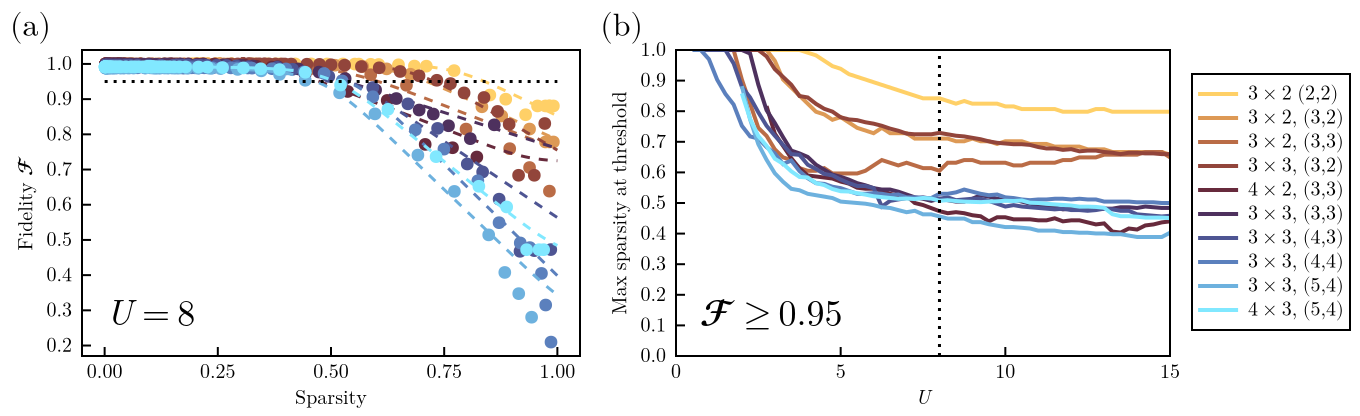

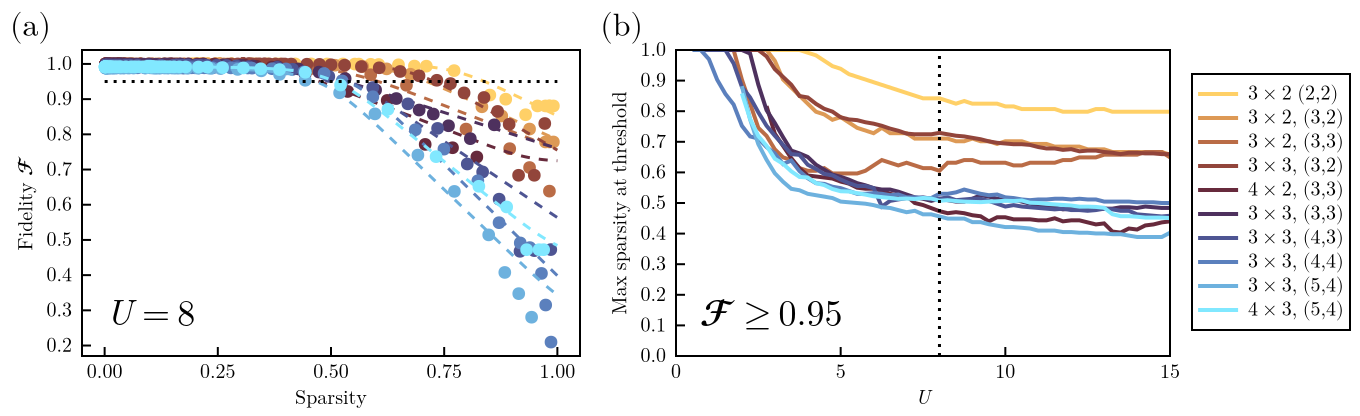

In [34]:
softplus(x, b) = max(x, zero(x)) + log(b) + log1p(exp(-abs(x)) / b)
scaled_softplus(x, p1, p2) = 1 / log(1 + p2) * softplus(p1 * x, p2)
# model(x,p) = @. 1 - (p[6]*scaled_softplus(p[5]*(x-1), p[1], p[2]) + (1-p[6])*scaled_softplus(p[5]*(x-1), p[3], p[4]))
# model(x,p) = @. (1-tanh(p[1]*(x-p[2])))/2  # too rigid/symmetric for this curve's asymmetric shoulder (SSE ~0.29 vs ~0.004 below)
model(x, p) = @. (1 - p[1] * (x - p[2]) / (1 + abs(p[1] * (x - p[2]))^p[3])^(1 / p[3])) / 2

rescale(x, p) = @. x * (p[2] - p[1]) + p[1]

antihermitian_val, custom_ref_state_arg_val = true, "slater"

# Load reference metadata for U values
ref_file_label = FILE_LABEL_PAIRS[1][2]
u_values = 0.25:0.25:15.0

hilbert_space_sizes = Int[]
fit_params = []
fit_errors = []
overlap_bounds = []
sparsity_data = []
norm_overlap_data = []
max_removed_data = []   # per system, per U: removed-term count that sparsity = 1 corresponds to (= total)
total_params_list = Int[]   # per system: total number of circuit parameters
u_indices = 2:60

for (color_i, (label, file_label, nelectrons)) in enumerate(FILE_LABEL_PAIRS)

    nsites = prod(parse_lattice_dimension(file_label))
    # filename = build_save_name_prefix(
    #     "pruning_analysis_trotter";
    #     sites=nsites,
    #     antihermitian=antihermitian_val,
    #     custom_ref_state_arg=custom_ref_state_arg_val,
    #     num_exponentials=2
    # )
    # pruning_analysis_path = joinpath(FOLDER, file_label, "$(filename).jld2")
    # if !isfile(pruning_analysis_path)
        filename = build_save_name_prefix(
            "pruning_analysis_trotter";
            sites=nsites,
            antihermitian=antihermitian_val,
            custom_ref_state_arg=custom_ref_state_arg_val,
            num_exponentials=1
        )
        pruning_analysis_path = joinpath(FOLDER, file_label, "$(filename).jld2")
    # end

    system_size = parse_lattice_dimension(file_label)
    meta_data_path = joinpath(FOLDER, file_label, "HubbardBasis_XDiag_$(system_size[1])x$(system_size[2])_nu_$(nelectrons[1])_nd_$(nelectrons[2]).h5")


    h5open(meta_data_path, "r") do data
        push!(hilbert_space_sizes, length(data["sectors/0/R_up_rep"][:]))
    end

    d = load(pruning_analysis_path)

    # total parameter count, from one of the coefficient files the pruning analysis was run on
    coeff_prefix = replace(basename(pruning_analysis_path), r"^pruning_analysis_" => "", r"\.jld2$" => "")
    coeff_files = filter(f -> startswith(f, "$(coeff_prefix)_u_") || startswith(f, "$(coeff_prefix)_u_build_u_"),
        readdir(joinpath(FOLDER, file_label)))
    isempty(coeff_files) && error("No coefficient files for $(coeff_prefix) in $(file_label)")
    push!(total_params_list, length(load_saved_dict(joinpath(FOLDER, file_label, first(coeff_files)))["coefficients"]))
    # sparsity is (# set to zero) / (total # of coefficients), as the Fig. 3 caption says (HANDOFF item 35);
    # so one unit of sparsity is the total parameter count, as in the non-Slater cell below
    push!(max_removed_data, fill(total_params_list[end], length(u_indices)))

    curr_fit_params = Vector{Any}(undef, length(u_indices))
    curr_fit_errors = Vector{Any}(undef, length(u_indices))
    curr_overlap_bounds = Vector{Any}(undef, length(u_indices))
    curr_sparsity_data = Vector{Any}(undef, length(u_indices))
    curr_norm_overlap_data = Vector{Any}(undef, length(u_indices))
    println(label)
    for (idx, i) in collect(enumerate(u_indices))
        filt = d["removed_terms"][:, i] .> 0
        if abs(u_values[i] - 8) < 0.1 
            println("ERROR: $((1 .- abs.(d["error_data"][:, i][filt])) .* 100)")
        end

        err = max.(abs.(d["error_data"][:, i][filt]), 1e-16)
        overlap = 1 .- err

        sparsity = d["removed_terms"][:, i][filt] ./ total_params_list[end]
        norm_overlap = (overlap .- overlap[end]) ./ (overlap[1] .- overlap[end])
        curr_overlap_bounds[idx] = [overlap[end], overlap[1]]

        filt2 = norm_overlap .> norm_overlap[end]

        weight = min.(1 ./ (1 .- overlap) .^ 2, 1e6)  # cap: max(err,1e-16) floor otherwise lets weight blow up to ~1e27 and makes curve_fit's normal equations singular
        # println(sparsity[filt2])
        # println(norm_overlap[filt2])
        # fig = Figure()
        # ax = Axis(fig[1,1], yscale=log10)
        # l1= lines!(ax, sparsity[filt2], 1 .-norm_overlap[filt2], label="data")
        # l2 = lines!(ax, sparsity[filt2], 1 .-model(sparsity[filt2],[6.0,1.0,1.0]), label="personal")
        fit = curve_fit(
            model,
            sparsity[filt2],
            norm_overlap[filt2],
            weight[filt2],
            [1.0, 1.0, 1.0],
            lower=[-Inf, -Inf, 0.1],
            upper=[Inf, Inf, 10.0]
        )

        # println(fit.param)
        # l3 = lines!(ax, sparsity[filt2], 1 .-model(sparsity[filt2],fit.param), label="fit")
        # Legend(fig[1,1], [l1, l2, l3], ["data","personal", "fit"])
        # display(fig)

        errs = try
            stderror(fit)
        catch
            zeros(length(fit.param))
        end

        curr_fit_params[idx] = copy(fit.param)
        curr_fit_errors[idx] = copy(errs)
        curr_sparsity_data[idx] = sparsity[filt2]
        curr_norm_overlap_data[idx] = norm_overlap[filt2]
    end

    push!(fit_params, curr_fit_params)
    push!(fit_errors, curr_fit_errors)
    push!(overlap_bounds, curr_overlap_bounds)
    push!(sparsity_data, curr_sparsity_data)
    push!(norm_overlap_data, curr_norm_overlap_data)
end

output_dir = joinpath(@__DIR__, "good_images", "final")
if !isdir(output_dir)
    mkpath(output_dir)
end

cmap = cmap2(length(FILE_LABEL_PAIRS))


# Combined Calculation: Plot pruning curves and max sparsity at overlap threshold in a single figure
plot_pruning_and_sparsity_at_threshold(
    u_values, u_indices, FILE_LABEL_PAIRS, fit_params,
    overlap_bounds, sparsity_data, norm_overlap_data, hilbert_space_sizes, output_dir,
    antihermitian_val, custom_ref_state_arg_val, cmap; selected_U=8, threshold=0.95,
    max_removed_data, total_params_list
)


In [ ]:
# ==============================================================================
# Pruning for the non-Slater reference state: the ED ground state at U = 0.25
# (U index 1 of each system's U grid), Trotter, 1 exponential, antihermitian.
# Any system whose scan coefficients or pruning analysis are missing (or whose
# pruning analysis is older than its coefficients) gets Slurm jobs submitted:
# the scan over the missing U indices, then run_pruning_analysis.jl once it
# succeeds. Re-run this cell after the jobs finish to include those systems.
# ==============================================================================
nonslater_ref_u = 0.25
nonslater_num_exp = 1
nonslater_u_indices = 2:60   # target U indices; index 1 is the reference state itself
submit_missing = true
slurm_args = `--mem=20G --cpus-per-task=20 --time=7-00:00:00 --partition=kim`
jobs_dir = "/home/jek354/research/ML-signproblem/jobs"

function nonslater_status(file_label)
    folder = joinpath(FOLDER, file_label)
    U_vals = load_ED_data(folder; verbose=false, sign_convention=:spin_first, use_slater_reference=false)[1]
    isapprox(U_vals[1], nonslater_ref_u) ||
        error("$(file_label): reference U index 1 is U=$(U_vals[1]), not $(nonslater_ref_u)")
    nsites = prod(parse_lattice_dimension(file_label))
    coeff_prefix = build_save_name_prefix(:trotter; sites=nsites, antihermitian=true, num_exponentials=nonslater_num_exp)
    coeff_file(i) = joinpath(folder, "$(coeff_prefix)_u_$(i).jld2")
    missing_u = [i for i in nonslater_u_indices if !isfile(coeff_file(i))]
    pruning_path = joinpath(folder, build_save_name_prefix("pruning_analysis_trotter"; sites=nsites,
        antihermitian=true, num_exponentials=nonslater_num_exp) * ".jld2")
    existing = [coeff_file(i) for i in nonslater_u_indices if isfile(coeff_file(i))]
    pruning_current = isfile(pruning_path) && !isempty(existing) &&
        mtime(pruning_path) >= maximum(mtime.(existing))
    return (; folder, U_vals, missing_u, pruning_path, pruning_current, coeff_file=first(existing, 1))
end

function submit_job(name, script_and_args; dependency=nothing)
    cmd_str = "cd '$(@__DIR__)' && julia --project=.. $(script_and_args)"
    dep = isnothing(dependency) ? `` : `--dependency=afterok:$(dependency)`
    out = read(`sbatch $slurm_args $dep --job-name=$name --output=$(joinpath(jobs_dir, "$name.out")) --error=$(joinpath(jobs_dir, "$name.err")) --wrap=$cmd_str`, String)
    m = match(r"Submitted batch job (\d+)", out)
    isnothing(m) && error("sbatch failed for $name: $out")
    println("  submitted $name (job $(m.captures[1]))")
    return m.captures[1]
end

queued_jobs = Set(split(read(`squeue -u $(ENV["USER"]) -h -o %j`, String)))
nonslater_ready = Bool[]
nonslater_status_list = []
for (label, file_label, _) in FILE_LABEL_PAIRS
    st = nonslater_status(file_label)
    push!(nonslater_status_list, st)
    push!(nonslater_ready, isempty(st.missing_u) && st.pruning_current)
    nonslater_ready[end] && continue

    tag = replace(file_label, " " => "", "=" => "", "(" => "", ")" => "", "," => "_")
    scan_name, prune_name = "trotter_nonslater_scan_$(tag)", "trotter_nonslater_prune_$(tag)"
    println("$(file_label): $(length(st.missing_u)) U indices missing, pruning analysis ",
        st.pruning_current ? "current" : "missing/stale")
    if scan_name in queued_jobs || prune_name in queued_jobs
        println("  jobs already queued/running")
        continue
    end
    submit_missing || continue
    mkpath(jobs_dir)
    scan_job = nothing
    if !isempty(st.missing_u)
        # a range scan warm-starts each U from its neighbour, so cover every missing index
        hi, lo = maximum(st.missing_u), minimum(st.missing_u)
        u_args = hi == lo ? "$hi" : "$hi $lo"
        scan_job = submit_job(scan_name, "run_trotter_scan_optimization.jl '$(st.folder)' $u_args --antihermitian --loss=overlap --num_exponentials=$(nonslater_num_exp)")
    end
    submit_job(prune_name, "run_pruning_analysis.jl '$(st.folder)' --type=trotter --antihermitian --num_exponentials=$(nonslater_num_exp)";
        dependency=scan_job)
end

# Fits for the systems whose data is complete, in the same form as fig 3, except that
# sparsity is removed / total parameters directly (the non-Slater U grid has no
# prepended U = 0 entry, so removed_terms column i is U = U_vals[i])
ns_pairs = FILE_LABEL_PAIRS[nonslater_ready]
ns_fit_params, ns_overlap_bounds, ns_sparsity_data, ns_norm_overlap_data = [], [], [], []
ns_max_removed_data, ns_total_params = [], Int[]
for st in nonslater_status_list[nonslater_ready]
    d = load(st.pruning_path)
    n_total = length(load_saved_dict(only(st.coeff_file))["coefficients"])
    fits, bounds_u, sparsities, norm_overlaps = [], [], [], []
    for i in nonslater_u_indices
        filt = d["removed_terms"][:, i] .> 0
        overlap = 1 .- max.(abs.(d["error_data"][:, i][filt]), 1e-16)
        sparsity = d["removed_terms"][:, i][filt] ./ n_total
        norm_overlap = (overlap .- overlap[end]) ./ (overlap[1] .- overlap[end])
        filt2 = norm_overlap .> norm_overlap[end]
        weight = min.(1 ./ (1 .- overlap) .^ 2, 1e6)
        fit = curve_fit(model, sparsity[filt2], norm_overlap[filt2], weight[filt2], [1.0, 1.0, 1.0],
            lower=[-Inf, -Inf, 0.1], upper=[Inf, Inf, 10.0])
        push!(fits, copy(fit.param))
        push!(bounds_u, [overlap[end], overlap[1]])
        push!(sparsities, sparsity[filt2])
        push!(norm_overlaps, norm_overlap[filt2])
    end
    push!(ns_fit_params, fits); push!(ns_overlap_bounds, bounds_u)
    push!(ns_sparsity_data, sparsities); push!(ns_norm_overlap_data, norm_overlaps)
    # sparsity is already removed / total, so one unit of sparsity is n_total parameters
    push!(ns_max_removed_data, fill(n_total, length(nonslater_u_indices)))
    push!(ns_total_params, n_total)
end

println("Non-Slater data complete for $(sum(nonslater_ready)) / $(length(FILE_LABEL_PAIRS)) systems")
if any(nonslater_ready)
    ns_U_vals = nonslater_status_list[findfirst(nonslater_ready)].U_vals
    plot_pruning_and_sparsity_at_threshold(
        ns_U_vals, nonslater_u_indices, ns_pairs, ns_fit_params,
        ns_overlap_bounds, ns_sparsity_data, ns_norm_overlap_data, fill(0, length(ns_pairs)), output_dir,
        true, "nonslater_U=$(nonslater_ref_u)", cmap[nonslater_ready]; selected_U=8, threshold=0.99,
        max_removed_data=ns_max_removed_data, total_params_list=ns_total_params,
        csv_names=("fig3a_nonslater.csv", "fig3b_nonslater.csv")
    )
end

In [13]:
1094*2*0.67

1465.96

In [17]:
path = "/home/jek354/research/data/new_data/data_h5_fixed/N=(4, 3)_3x3/HubbardBasis_XDiag_3x3_nu_4_nd_3.h5"
h5open(path, "r") do data
    display(data["sectors/0/R_up_rep"][:])
end

1176-element Vector{UInt32}:
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
 0x0000000f
          ⋮
 0x00000066
 0x00000066
 0x00000066
 0x00000066
 0x00000066
 0x00000066
 0x00000066
 0x00000066
 0x00000066

# Sandbox


0.9995028061336335 2.907862445401116e-10


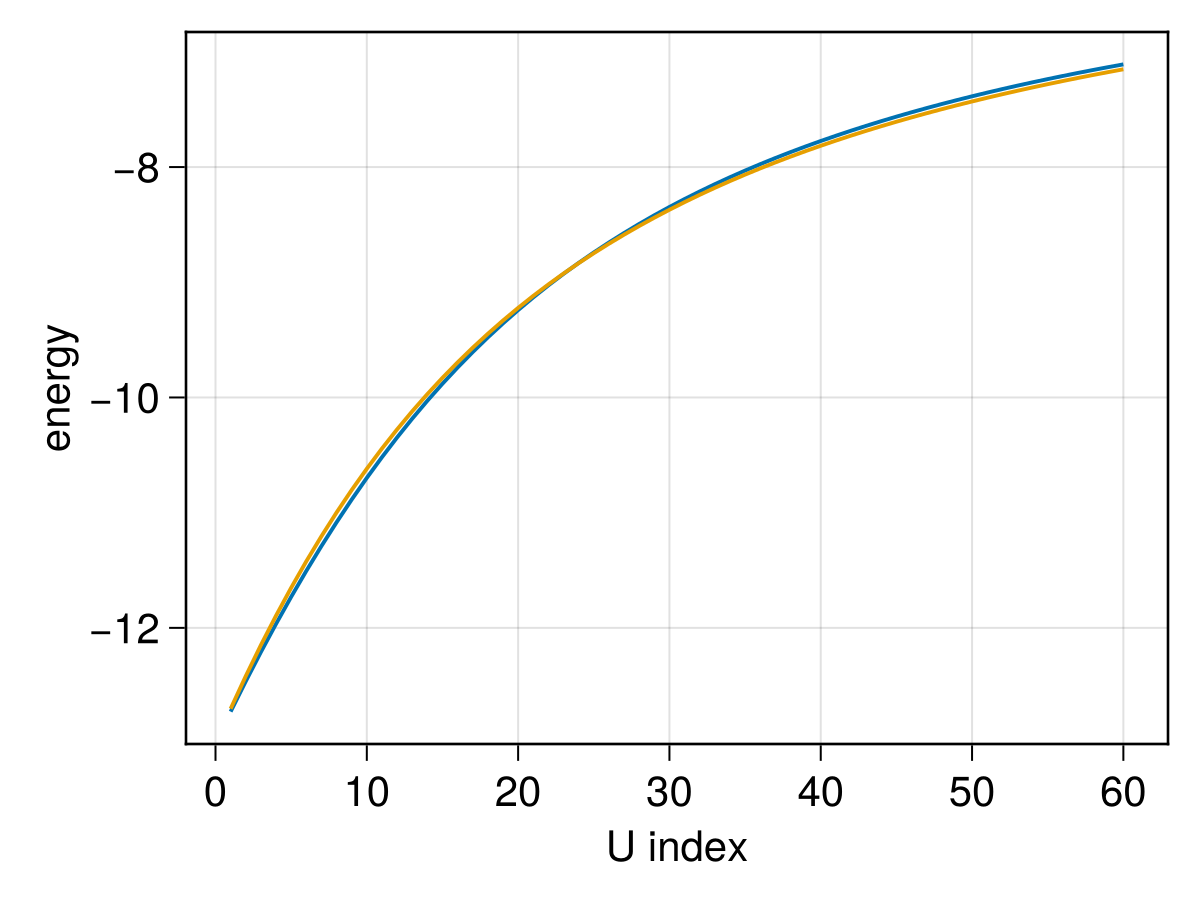

CairoMakie.Screen{IMAGE}


In [2]:
h5open(joinpath(FOLDER, "N=(4, 3)_3x3","HubbardED_XDiag_momSlater_3x3_nu_4_nd_3_t_1_m_2_sectors_(3).h5"), "r") do data
    # N = Tuple(convert.(Int, [read(data, "metadata/nu"), read(data, "metadata/nd")]))

    # Lvec = convert.(Int, read(data, "metadata/Lvec"))
    # U_values = Float64.(read(data, "data/uvec"))
    # kvecs = convert.(Int, read(data, "metadata/qvecs"))

    # key_labels = [parse(Int, k) for k in keys(data["data/energies"])]
    v1 = data["data/evecs/3"][:,1,:]
    v2 = data["data/evecs/3"][:,2,:]

    indices = select_continuous_state_indices(data["data/evecs/3"][:,:,:], data["data/energies/3"][:, :])
    energies = data["data/energies/3"][1, :]
    for i in axes(v1[:, end-1],2)
        println("$(abs(v1[:,i]'*v1[:, i+1])) $(abs(v1[:,i]'*v2[:, i+1]))")
    end
    fig = Figure()
    ax = Axis(fig[1, 1], xlabel="U index", ylabel="energy")
    lines!(ax, [data["data/energies/3"][indices[i], i] for i in eachindex(indices)])
    lines!(ax, [data["data/energies/3"][3 - indices[i], i] for i in eachindex(indices)])
    display(fig)
    # all_E = [real.(read(data, "data/energies/$(k)"))[1, :] for k in key_labels]

    # display(plot(all_E[1]))
    # k_min = find_best_energy_sector(all_E, U_values; labels=key_labels, data=data, su2_symmetry=su2_symmetry)
end

# Slater Determinant Non-Interacting State Effects Analysis

In this section, we analyze the definitive effects of the existence of a unique, non-degenerate Slater determinant non-interacting state on the optimization performance.

We compare:
- **Systems containing Slater non-interacting state**:
  - $3\times 3$ $(5, 4)$ and $4\times 3$ $(5, 4)$
- **Systems NOT containing Slater non-interacting state**:
  - $3\times 3$ $(4, 4)$ and $4\times 3$ $(4, 4)$

We plot:
1. **Interaction loss as a function of $U$** for each of these systems. We make solid lines for the runs using the Slater reference state, and dashed lines for those that do not use it.
2. **Loss as a function of the Hilbert space size** at a selected U value ($U = 8.0$). We draw one line connecting the $(5, 4)$ systems (where the Slater non-interacting state exists, plotted as dashed line segments) and one connecting the $(4, 4)$ systems (where the Slater state does not exist, plotted as solid line segments) for both Slater and non-Slater reference runs. We also annotate the degrees of freedom (number of parameters) for each system.

In [ ]:
# Plot 1: Interaction loss as a function of U for the four systems.
# Solid for Slater reference, dashed for not-Slater.

using CairoMakie
using JLD2
using HDF5
using LaTeXStrings

const SYSTEMS_PLOT1 = [
    ("3x3 (5,4)", "N=(5, 4)_3x3", 9),
    ("4x3 (5,4)", "N=(5, 4)_4x3", 12),
    ("3x3 (4,4)", "N=(4, 4)_3x3", 9),
    ("4x3 (4,4)", "N=(4, 4)_4x3", 12)
]

fig1 = Figure(size=(1000, 600))
ax1 = Axis(fig1[1, 1],
    xlabel = L"U",
    ylabel = L"1 - |\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2",
    yscale = log10,
    title = "Interaction Loss vs U"
)

colors1 = [:blue, :forestgreen, :crimson, :purple]
u_indices = 2:60

for (idx, (name, dir, sites)) in enumerate(SYSTEMS_PLOT1)
    sys_dir = joinpath(FOLDER, dir)
    if !isdir(sys_dir)
        continue
    end
    
    # 1. Slater reference run (solid)
    prefix_slater = "trotter_N=\$(sites)_ref_slater_antihermitian"
    u_vals_s = Float64[]
    losses_s = Float64[]
    for u_idx in u_indices
        f = joinpath(sys_dir, "\$(prefix_slater)_u_\$(u_idx).jld2")
        if isfile(f)
            d = load_saved_dict(f)
            push!(u_vals_s, (u_idx - 1) * 0.25)
            push!(losses_s, max(length(d["metrics"]["loss"]) >= 2 ? d["metrics"]["loss"][2] : d["metrics"]["loss"][1], 1e-12))
        end
    end
    
    # 2. Non-Slater reference run (dashed)
    prefix_noslater = "trotter_N=\$(sites)_antihermitian"
    u_vals_n = Float64[]
    losses_n = Float64[]
    for u_idx in u_indices
        f = joinpath(sys_dir, "\$(prefix_noslater)_u_\$(u_idx).jld2")
        if isfile(f)
            d = load_saved_dict(f)
            push!(u_vals_n, (u_idx - 1) * 0.25)
            push!(losses_n, max(length(d["metrics"]["loss"]) >= 2 ? d["metrics"]["loss"][2] : d["metrics"]["loss"][1], 1e-12))
        end
    end
    
    # Plot Slater (solid)
    if !isempty(losses_s)
        lines!(ax1, u_vals_s, losses_s, color=colors1[idx], linewidth=2.5, linestyle=:solid, label="\$name (Slater)")
    end
    # Plot non-Slater (dashed)
    if !isempty(losses_n)
        lines!(ax1, u_vals_n, losses_n, color=colors1[idx], linewidth=2.5, linestyle=:dash, label="\$name (No Slater)")
    end
end

axislegend(ax1, position=:rt, backgroundcolor=(:white, 0.8))
display(fig1)


In [ ]:
# Plot 2: Loss as a function of Hilbert space size for U = 8.0.

using CairoMakie
using JLD2
using HDF5
using LaTeXStrings

target_u_idx = 33 # corresponds to U = 8.0
target_u_val = (target_u_idx - 1) * 0.25

const SYSTEMS_PLOT2 = [
    ("3x3 (5,4)", "N=(5, 4)_3x3", 9, 1764, 504, true),
    ("4x3 (5,4)", "N=(5, 4)_4x3", 12, 32670, 1368, true),
    ("3x3 (4,4)", "N=(4, 4)_3x3", 9, 1764, 504, false),
    ("4x3 (4,4)", "N=(4, 4)_4x3", 12, 20439, 1368, false)
]

fig2 = Figure(size=(1000, 600))
ax2 = Axis(fig2[1, 1],
    xlabel = "Hilbert Space Size",
    ylabel = L"1 - |\langle \Psi_{\mathbf{K}}(U)|\mathcal{U}_A|\Phi_{\mathbf{K}}\rangle|^2",
    yscale = log10,
    xscale = log10,
    title = "Loss vs Hilbert Space Size at U = \$target_u_val"
)
xlims!(ax2, 1000, 120000)

slater_exists_x_s = Float64[]
slater_exists_y_s = Float64[]
slater_noexists_x_s = Float64[]
slater_noexists_y_s = Float64[]

slater_exists_x_n = Float64[]
slater_exists_y_n = Float64[]
slater_noexists_x_n = Float64[]
slater_noexists_y_n = Float64[]

for (name, dir, sites, hs_size, dof, exists) in SYSTEMS_PLOT2
    sys_dir = joinpath(FOLDER, dir)
    if !isdir(sys_dir)
        continue
    end
    
    # 1. Slater reference
    f_s = joinpath(sys_dir, "trotter_N=\$(sites)_ref_slater_antihermitian_u_\$(target_u_idx).jld2")
    if isfile(f_s)
        d = load_saved_dict(f_s)
        loss_val = max(length(d["metrics"]["loss"]) >= 2 ? d["metrics"]["loss"][2] : d["metrics"]["loss"][1], 1e-12)
        if exists
            push!(slater_exists_x_s, hs_size)
            push!(slater_exists_y_s, loss_val)
        else
            push!(slater_noexists_x_s, hs_size)
            push!(slater_noexists_y_s, loss_val)
        end
        text!(ax2, hs_size, loss_val; text = "  \$name (dof=\$dof)", align = (:left, :center), fontsize = 12)
    end
    
    # 2. No Slater reference
    f_n = joinpath(sys_dir, "trotter_N=\$(sites)_antihermitian_u_\$(target_u_idx).jld2")
    if isfile(f_n)
        d = load_saved_dict(f_n)
        loss_val = max(length(d["metrics"]["loss"]) >= 2 ? d["metrics"]["loss"][2] : d["metrics"]["loss"][1], 1e-12)
        if exists
            push!(slater_exists_x_n, hs_size)
            push!(slater_exists_y_n, loss_val)
        else
            push!(slater_noexists_x_n, hs_size)
            push!(slater_noexists_y_n, loss_val)
        end
        text!(ax2, hs_size, loss_val; text = "  \$name (dof=\$dof)", align = (:left, :center), fontsize = 12)
    end
end

# Draw lines
if length(slater_exists_x_s) == 2
    p = sortperm(slater_exists_x_s)
    lines!(ax2, slater_exists_x_s[p], slater_exists_y_s[p], color=:blue, linestyle=:dash, linewidth=2.5)
end
if length(slater_noexists_x_s) == 2
    p = sortperm(slater_noexists_x_s)
    lines!(ax2, slater_noexists_x_s[p], slater_noexists_y_s[p], color=:blue, linestyle=:solid, linewidth=2.5)
end

if length(slater_exists_x_n) == 2
    p = sortperm(slater_exists_x_n)
    lines!(ax2, slater_exists_x_n[p], slater_exists_y_n[p], color=:crimson, linestyle=:dash, linewidth=2.5)
end
if length(slater_noexists_x_n) == 2
    p = sortperm(slater_noexists_x_n)
    lines!(ax2, slater_noexists_x_n[p], slater_noexists_y_n[p], color=:crimson, linestyle=:solid, linewidth=2.5)
end

scatter!(ax2, [slater_exists_x_s; slater_noexists_x_s], [slater_exists_y_s; slater_noexists_y_s], color=:blue, marker=:circle, markersize=10)
scatter!(ax2, [slater_exists_x_n; slater_noexists_x_n], [slater_exists_y_n; slater_noexists_y_n], color=:crimson, marker=:circle, markersize=10)

elem_blue = LineElement(color=:blue, linestyle=:solid, linewidth=2.5)
elem_red = LineElement(color=:crimson, linestyle=:solid, linewidth=2.5)
elem_solid = LineElement(color=:black, linestyle=:solid, linewidth=2.5)
elem_dash = LineElement(color=:black, linestyle=:dash, linewidth=2.5)

Legend(fig2[1, 2],
    [elem_blue, elem_red, elem_solid, elem_dash],
    ["Slater Reference", "No Slater Reference", "Slater State Doesn\'t Exist", "Slater State Exists"]
)
display(fig2)
